In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load train and test data
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")

y_train_cls = pd.read_csv("../data/y_train_cls.csv").squeeze("columns")
y_test_cls = pd.read_csv("../data/y_test_cls.csv").squeeze("columns")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target (Classification):", y_train_cls.shape)
print("Testing target (Classification):", y_test_cls.shape)

Training features: (58274, 9)
Testing features: (14569, 9)
Training target (Classification): (58274,)
Testing target (Classification): (14569,)


In [2]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['ChargerCompany', 'ChargerType', 'StartHour', 'StartDayOfWeek', 'StartMonth', 'StartYear', 'IsWeekend']
Categorical features: ['Location', 'TimePeriod']


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_22736\3858876401.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [3]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [4]:
# Classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

In [5]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train_cls)

    predictions = pipeline.predict(X_test)
    preds_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else predictions

    acc = accuracy_score(y_test_cls, predictions)
    prec = precision_score(y_test_cls, predictions)
    rec = recall_score(y_test_cls, predictions)
    f1 = f1_score(y_test_cls, predictions)
    auc = roc_auc_score(y_test_cls, preds_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    trained_models[name] = pipeline

    print(f"{name} completed - Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, ROC AUC: {auc:.4f}")

Logistic Regression completed - Accuracy: 0.6293, F1 Score: 0.6287, ROC AUC: 0.6722


Decision Tree completed - Accuracy: 0.5992, F1 Score: 0.5778, ROC AUC: 0.6264


Random Forest completed - Accuracy: 0.6061, F1 Score: 0.6094, ROC AUC: 0.6519


Gradient Boosting completed - Accuracy: 0.6478, F1 Score: 0.6625, ROC AUC: 0.7052


XGBoost completed - Accuracy: 0.6542, F1 Score: 0.6686, ROC AUC: 0.7135


LightGBM completed - Accuracy: 0.6550, F1 Score: 0.6752, ROC AUC: 0.7165


In [6]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM,0.655021,0.635092,0.720613,0.675155,0.716452
1,XGBoost,0.654197,0.638959,0.701021,0.668553,0.713500
2,Gradient Boosting,0.647814,0.633094,0.694674,0.662456,0.705220
3,Logistic Regression,0.629350,0.626679,0.630657,0.628662,0.672235
4,Random Forest,0.606081,0.601370,0.617550,0.609353,0.651908
5,Decision Tree,0.599218,0.607051,0.551187,0.577771,0.626364


In [7]:
os.makedirs("../outputs", exist_ok=True)

results_df.to_csv(
    "../outputs/classification_model_comparison.csv",
    index=False
)
print("Saved model comparison to ../outputs/classification_model_comparison.csv")

Saved model comparison to ../outputs/classification_model_comparison.csv


Saved comparison chart to ../outputs/classification_model_comparison.png


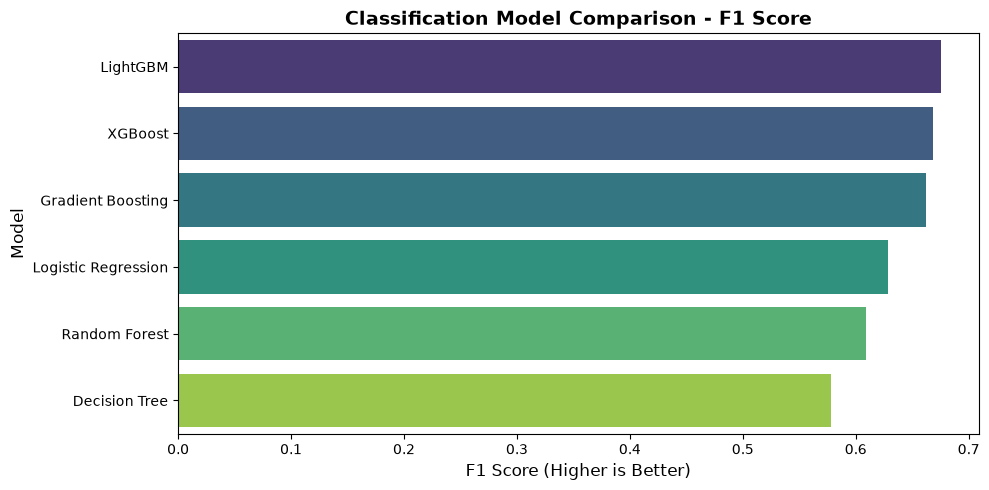

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="F1 Score",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Classification Model Comparison - F1 Score", fontsize=14, fontweight="bold")
plt.xlabel("F1 Score (Higher is Better)", fontsize=12)
plt.ylabel("Model", fontsize=12)

plt.savefig("../outputs/classification_model_comparison.png", dpi=300, bbox_inches="tight")
print("Saved comparison chart to ../outputs/classification_model_comparison.png")

plt.tight_layout()
plt.show()

In [9]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

os.makedirs("../trained_models", exist_ok=True)

joblib.dump(
    best_model,
    "../trained_models/best_classification_model.pkl"
)

print("Best Model:", best_model_name)
print("Model saved successfully to ../trained_models/best_classification_model.pkl")

Best Model: LightGBM
Model saved successfully to ../trained_models/best_classification_model.pkl


In [10]:
tree_models = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM"
]

importance_model_name = best_model_name if best_model_name in tree_models else "Random Forest"

importance_pipeline = trained_models[importance_model_name]

feature_names = (
    importance_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    importance_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(15))

,Feature,Importance
0,num__StartHour,745
1,num__StartMonth,530
2,num__StartDayOfWeek,218
3,num__ChargerCompany,198
4,num__ChargerType,148
5,cat__Location_market,144
6,cat__Location_apartment,130
7,cat__Location_resort,127
8,cat__Location_hotel,116
9,cat__Location_public area,86


Saved feature importance chart to ../outputs/classification_feature_importance.png


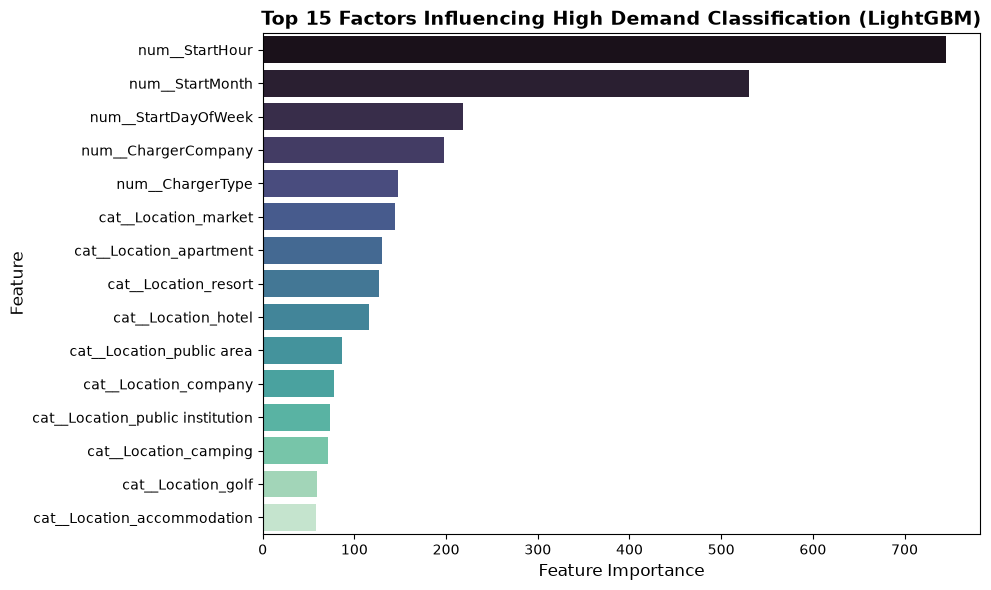

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="mako",
    legend=False
)

plt.title(f"Top 15 Factors Influencing High Demand Classification ({importance_model_name})", fontsize=14, fontweight="bold")
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.savefig("../outputs/classification_feature_importance.png", dpi=300, bbox_inches="tight")
print("Saved feature importance chart to ../outputs/classification_feature_importance.png")

plt.tight_layout()
plt.show()

Saved confusion matrix chart to ../outputs/classification_confusion_matrix.png


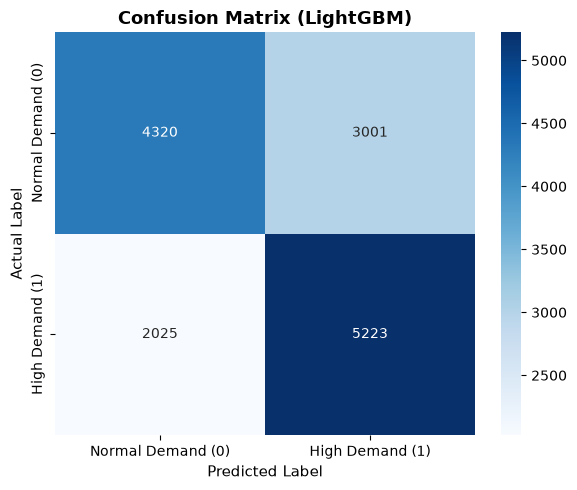

===== Classification Report =====
               precision    recall  f1-score   support

Normal Demand       0.68      0.59      0.63      7321
  High Demand       0.64      0.72      0.68      7248

     accuracy                           0.66     14569
    macro avg       0.66      0.66      0.65     14569
 weighted avg       0.66      0.66      0.65     14569



In [12]:
# Load the saved model to verify inference
loaded_model = joblib.load(
    "../trained_models/best_classification_model.pkl"
)

# Predict high vs normal demand
predictions = loaded_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test_cls, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Demand (0)", "High Demand (1)"],
    yticklabels=["Normal Demand (0)", "High Demand (1)"]
)
plt.title(f"Confusion Matrix ({best_model_name})", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)

plt.savefig("../outputs/classification_confusion_matrix.png", dpi=300, bbox_inches="tight")
print("Saved confusion matrix chart to ../outputs/classification_confusion_matrix.png")

plt.tight_layout()
plt.show()

# Display classification report
print("===== Classification Report =====")
print(classification_report(y_test_cls, predictions, target_names=["Normal Demand", "High Demand"]))